# 01 · Exploratory analysis: housing vacancy in Ciudad Juárez

Joins INEGI Census 2020 (AGEB level) with IMIP layers to see what is associated with vacant housing.

Data: `data/raw/` (re-download with `python scripts/download_data.py`).

In [1]:
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")
RAW = Path("../data/raw")
IMIP = RAW / "imip"
UTM = 32613  # UTM zone 13N, distances in meters

def imip(name):
    return gpd.read_file(IMIP / f"{name}.geojson").to_crs(UTM)

## Census 2020 by AGEB
Target: `% vacant = VIVPAR_DES / TVIVPAR`. INEGI masks small values as `*`, read as NaN. AGEBs with fewer than 50 dwellings are dropped.

In [2]:
censo = pd.read_csv(RAW / "juarez_censo2020_ageb_manzana.csv", dtype=str)
ageb_c = censo[censo.NOM_LOC == "Total AGEB urbana"].copy()
for k in ["POBTOT", "TVIVPAR", "VIVPAR_DES", "GRAPROES"]:
    ageb_c[k] = pd.to_numeric(ageb_c[k], errors="coerce")
ageb_c["CVEGEO"] = ageb_c.ENTIDAD + ageb_c.MUN + ageb_c.LOC + ageb_c.AGEB

a = gpd.read_file(RAW / "inegi_marco_geo_2020_juarez.gpkg", layer="ageb").to_crs(UTM)
a = a.merge(ageb_c[["CVEGEO", "POBTOT", "TVIVPAR", "VIVPAR_DES", "GRAPROES"]], on="CVEGEO")
a = a[a.TVIVPAR >= 50].copy()
a["pct_vacant"] = a.VIVPAR_DES / a.TVIVPAR * 100
print(len(a), "AGEBs |", int(a.VIVPAR_DES.sum()), "vacant homes")

567 AGEBs | 55213 vacant homes


## Spatial features
Computed from each AGEB centroid (approximation: 51 AGEBs fall outside the IMIP growth polygons).

In [3]:
cen = a.copy()
cen["geometry"] = a.centroid

def value_at_centroid(layer, col):
    j = gpd.sjoin(cen[["CVEGEO", "geometry"]], layer[[col, "geometry"]], how="left", predicate="within")
    return j.drop_duplicates("CVEGEO").set_index("CVEGEO").loc[a.CVEGEO, col].values

a["year_urbanized"] = value_at_centroid(imip("crecimiento_historico"), "CRECIMI")
a["property_value"] = pd.to_numeric(value_at_centroid(imip("valor_catastral_zonas_2025"), "VALORCATA"), errors="coerce")

maq, brt, salud = imip("maquilas_2022"), imip("estaciones_brt"), imip("unidades_medicas")
a["km_maquila"] = cen.geometry.apply(lambda p: maq.distance(p).min() / 1000)
a["maquilas_3km"] = cen.geometry.apply(lambda p: (maq.distance(p) < 3000).sum())
a["km_brt"] = cen.geometry.apply(lambda p: brt.distance(p).min() / 1000)
a["km_health"] = cen.geometry.apply(lambda p: salud.distance(p).min() / 1000)
centro = gpd.GeoSeries.from_xy([-106.4845], [31.7395], crs=4326).to_crs(UTM)[0]  # approx. historic center
a["km_center"] = cen.distance(centro) / 1000

for y in [2020, 2025]:
    n = gpd.sjoin(imip(f"delitos_{y}"), a[["CVEGEO", "geometry"]], predicate="within").groupby("CVEGEO").size()
    a[f"crimes{y}_per1000"] = a.CVEGEO.map(n).fillna(0) / a.POBTOT * 1000

## What is associated with vacancy?
Spearman rank correlation (robust to outliers, no linearity assumption). Exploratory only, not causal.

In [4]:
cols = ["year_urbanized", "km_center", "km_maquila", "maquilas_3km", "km_brt", "km_health",
        "crimes2020_per1000", "crimes2025_per1000", "property_value", "GRAPROES"]
a[cols + ["pct_vacant"]].corr("spearman")["pct_vacant"].drop("pct_vacant").sort_values().round(2)

year_urbanized       -0.41
maquilas_3km         -0.32
km_center            -0.30
property_value       -0.19
GRAPROES             -0.16
km_health            -0.08
km_brt                0.02
km_maquila            0.11
crimes2025_per1000    0.17
crimes2020_per1000    0.22
Name: pct_vacant, dtype: float64

In [5]:
a["decade"] = a.year_urbanized // 10 * 10
a.groupby("decade").agg(agebs=("CVEGEO", "size"), median_pct_vacant=("pct_vacant", "median"),
                        vacant_homes=("VIVPAR_DES", "sum")).round(1)

,agebs,median_pct_vacant,vacant_homes
decade,,,
1890.0,1,24.8,99.0
1910.0,4,30.1,449.0
1930.0,9,27.4,1457.0
1950.0,22,20.4,2431.0
1960.0,70,16.5,6597.0
1970.0,77,10.3,5392.0
1980.0,52,9.0,4121.0
1990.0,150,9.0,12045.0
2000.0,109,8.2,13765.0


In [6]:
# Top AGEBs by number of vacant homes: distant 2006-2008 developments dominate
a.nlargest(10, "VIVPAR_DES")[["CVEGEO", "year_urbanized", "pct_vacant", "VIVPAR_DES", "km_center", "maquilas_3km"]].round(1)

,CVEGEO,year_urbanized,pct_vacant,VIVPAR_DES,km_center,maquilas_3km
117,0803700018248,NaN,91.7,1076.0,22.6,1
591,0803700018021,NaN,36.4,967.0,24.7,17
5,0803700018106,2008.0,74.7,737.0,26.0,1
628,0803700018017,NaN,8.7,711.0,22.7,28
459,0803700017822,2008.0,20.1,514.0,21.0,43
632,080370001756A,1997.0,26.8,491.0,11.4,49
358,0803700016913,2006.0,19.9,472.0,15.1,104
397,0803700017894,2008.0,26.7,448.0,23.7,1
448,0803700017108,2020.0,14.9,398.0,14.2,51
113,0803700017926,2007.0,20.1,363.0,22.8,10


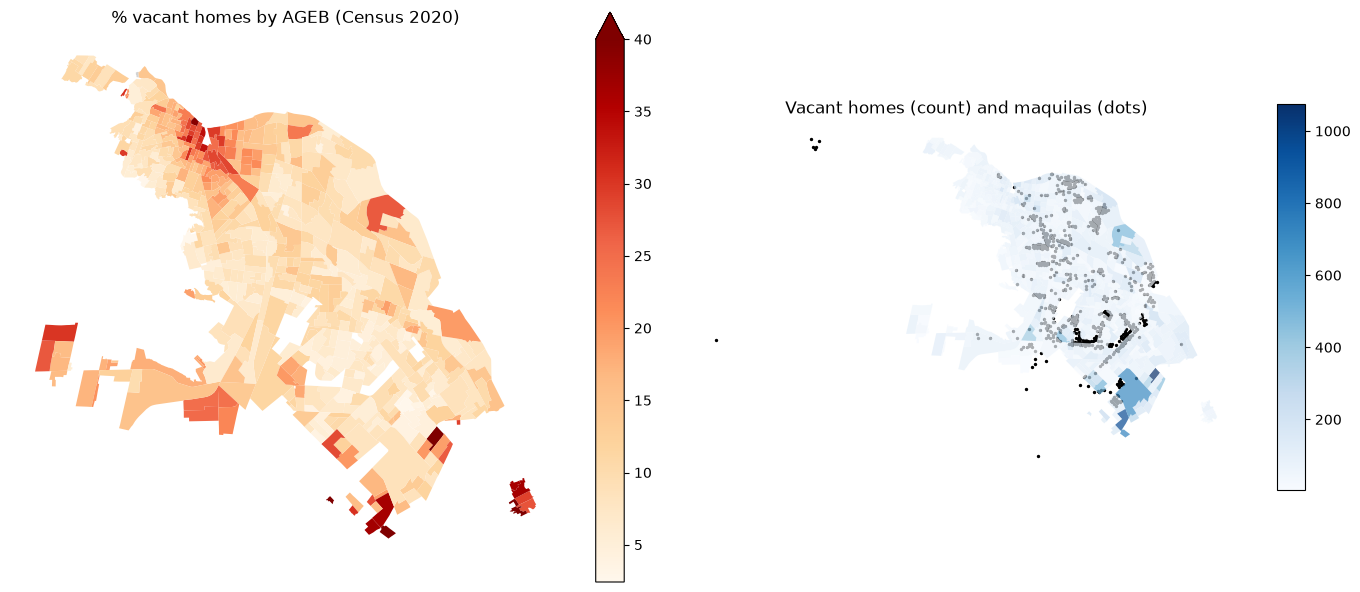

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
a.plot("pct_vacant", ax=ax[0], cmap="OrRd", legend=True, vmax=40, missing_kwds={"color": "lightgrey"})
ax[0].set_title("% vacant homes by AGEB (Census 2020)")
maq.plot(ax=ax[1], markersize=2, color="black")
a.plot("VIVPAR_DES", ax=ax[1], cmap="Blues", alpha=.7, legend=True)
ax[1].set_title("Vacant homes (count) and maquilas (dots)")
for x in ax: x.set_axis_off()
plt.tight_layout()

## Crime data as a monthly stream
IMIP publishes geolocated crime reports with month, hour and type; 2026 is updated through September.

In [8]:
d26 = gpd.read_file(IMIP / "delitos_2026.geojson")
print(d26.MES_NUMERO.value_counts().sort_index().to_dict())
d26.ID_GRUPO.value_counts().head(10)

{1: 715, 2: 715, 3: 731, 4: 802, 5: 730, 6: 713, 7: 809, 8: 746, 9: 747, 10: 1, 11: 1, 12: 1}


ID_GRUPO
DET. ORDEN PENDIENTE                   1520
VIOLENCIA FAMILIAR                      873
ROBO A CASA COMERCIAL CON VIOLENCIA     541
ROBO DE VEHICULO S/V                    409
DAÑOS                                   388
ROBO A CASA COMERCIAL SIN VIOLENCIA     347
ARMAS DECOMISADAS                       237
LESIONES OTROS                          184
HOMICIDIO C ARMA DE FUEGO               179
ROBO SIN VIOLENCIA                      167
Name: count, dtype: int64

In [9]:
a.drop(columns="geometry").to_csv("../data/ageb_features.csv", index=False)